# 1. RFM customer segmentation (Olist)

**Question:** which groups of customers exist, and what should marketing do with each?

**Data:** the Olist PostgreSQL database built in Project 1: about 95K real customers, orders before 1 Sep 2018 (the last complete month).

**Method:**
1. Describe each customer by **R**ecency (days since last order), **F**requency (orders) and **M**onetary (total spent).
2. Transform them so they are comparable (log for skewed values, then standardise).
3. Group similar customers with **K-Means**, choosing the number of groups with the elbow and silhouette methods *and* business sense.
4. Profile, name and recommend an action for each segment.

In [1]:
import sys
sys.path.append("..")  # so "import src..." works from the notebooks/ folder

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import BLUE, GREY, ORANGE, PROCESSED_DIR
from src.plots import save, setup_style
from src.rfm import choose_k, fit_segments, load_rfm, prepare_features, profile

setup_style()
pd.set_option("display.float_format", "{:,.2f}".format)

## Load RFM values from the database

In [2]:
rfm = load_rfm()
print(f"{len(rfm):,} customers")
rfm.describe()

94,983 customers


,recency_days,frequency,monetary
count,"94,983.00","94,983.00","94,983.00"
mean,240.33,1.03,142.07
std,152.98,0.21,216.07
min,2.00,1.00,0.85
25%,116.00,1.00,47.90
50%,221.00,1.00,89.89
75%,349.00,1.00,155.00
max,726.00,16.00,"13,440.00"


In [3]:
rfm["frequency"].value_counts().head(6).rename("customers").to_frame()

,customers
frequency,
1,92097
2,2650
3,188
4,29
5,9
6,5


**What this shows**

- **Frequency is almost always 1.** About 97% of customers bought only once (Project 1 found the same 3% repeat rate). Frequency will therefore mainly separate the small group of repeat buyers from everyone else.
- **Monetary is very skewed:** median R\$ 90, but the maximum is over R\$ 13,000. Without a log transform, K-Means would spend whole clusters on a handful of extreme spenders.

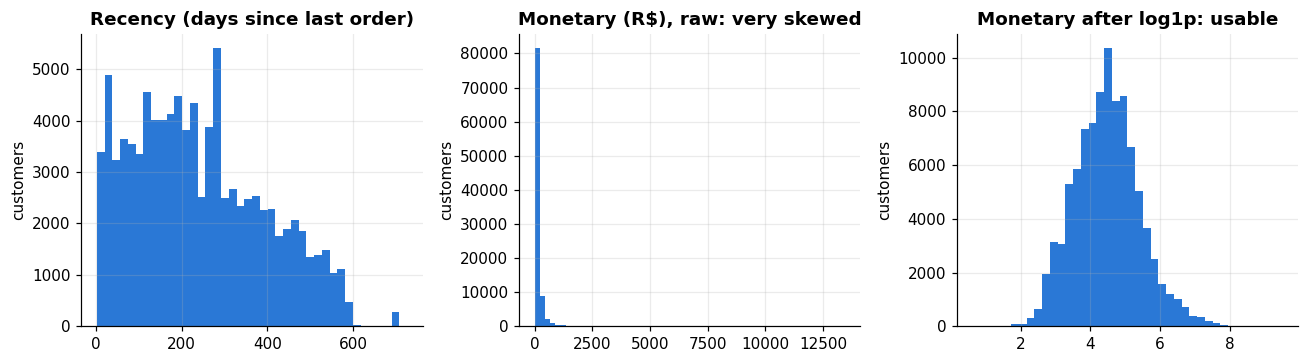

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(rfm["recency_days"], bins=40, color=BLUE)
axes[0].set_title("Recency (days since last order)")
axes[1].hist(rfm["monetary"], bins=60, color=BLUE)
axes[1].set_title("Monetary (R$), raw: very skewed")
axes[2].hist(np.log1p(rfm["monetary"]), bins=40, color=BLUE)
axes[2].set_title("Monetary after log1p: usable")
for ax in axes:
    ax.set_ylabel("customers")
fig.tight_layout()
save(fig, "rfm_distributions")

## Choosing the number of segments (k)

- **Inertia (elbow):** total distance from customers to their cluster centre. It always falls as k grows; we look for where the fall flattens.
- **Silhouette:** how clearly separated the clusters are (-1 to 1, higher is better).

In [5]:
X = prepare_features(rfm)
k_scores = choose_k(X)
k_scores

,k,inertia,silhouette
0,2,"217,970.64",0.31
1,3,"129,027.45",0.35
2,4,"88,339.23",0.36
3,5,"72,434.71",0.34
4,6,"61,254.10",0.34
5,7,"52,079.93",0.35
6,8,"46,882.01",0.35


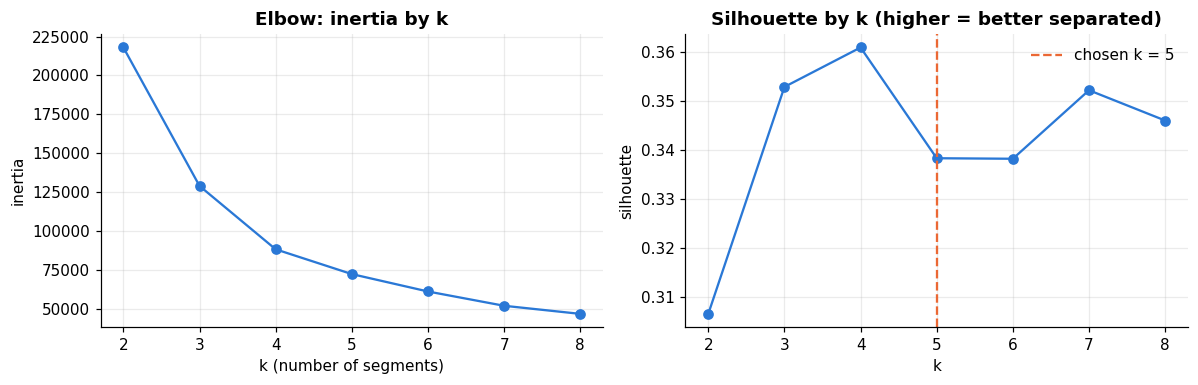

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.plot(k_scores["k"], k_scores["inertia"], marker="o", color=BLUE)
ax1.set(title="Elbow: inertia by k", xlabel="k (number of segments)", ylabel="inertia")
ax2.plot(k_scores["k"], k_scores["silhouette"], marker="o", color=BLUE)
ax2.axvline(5, color=ORANGE, linestyle="--", label="chosen k = 5")
ax2.set(title="Silhouette by k (higher = better separated)", xlabel="k", ylabel="silhouette")
ax2.legend(frameon=False)
fig.tight_layout()
save(fig, "rfm_choose_k")

**Decision: k = 5.**

The elbow flattens around k = 4–5, and silhouette is highest at k = 4 (0.36) with k = 5 close behind (0.34). The scores alone slightly favour 4, but comparing the two:

- **k = 4** merges different customers: its "lapsed" group averages only about R\$ 110, barely above the median spend, so it mixes small and big spenders.
- **k = 5** gives a clean 2 × 2 grid (recent/lapsed × big/small spenders) plus repeat buyers, and each group gets a clearly different action.

The metrics narrow the choice; **business usefulness decides**.

In [7]:
K = 5
segmented = fit_segments(rfm, X, K)
segments = profile(segmented)
segments[["segment", "customers", "share_of_customers_pct", "share_of_revenue_pct",
          "recency_days", "frequency", "monetary", "action"]]

,segment,customers,share_of_customers_pct,share_of_revenue_pct,recency_days,frequency,monetary,action
cluster,,,,,,,,
2,Recent big spenders,27449,28.90,42.11,121.51,1.00,207.03,Second-purchase offer within 30 days; cross-se...
1,Lapsed big spenders,18266,19.23,35.94,363.93,1.00,265.51,Win-back campaign with a personal offer; ask w...
4,Recent small spenders,28327,29.82,9.03,155.29,1.00,43.02,"Low-cost nudges: free-shipping threshold, bundles"
0,Lapsed small spenders,18055,19.01,7.36,432.05,1.00,55.00,Cheap automated emails only; don't spend much ...
3,Repeat buyers,2886,3.04,5.56,223.52,2.11,259.94,"Loyalty rewards, early access; ask for reviews..."


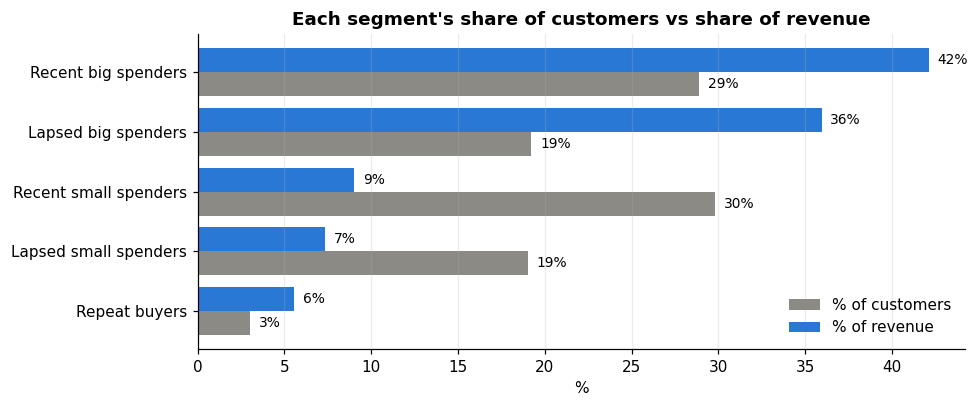

In [8]:
order = segments.sort_values("share_of_revenue_pct")
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(y - 0.2, order["share_of_customers_pct"], height=0.4, color=GREY, label="% of customers")
ax.barh(y + 0.2, order["share_of_revenue_pct"], height=0.4, color=BLUE, label="% of revenue")
for i, (c, r) in enumerate(zip(order["share_of_customers_pct"], order["share_of_revenue_pct"])):
    ax.text(c + 0.5, i - 0.2, f"{c:.0f}%", va="center", fontsize=9)
    ax.text(r + 0.5, i + 0.2, f"{r:.0f}%", va="center", fontsize=9)
ax.set_yticks(y, order["segment"])
ax.set_xlabel("%")
ax.set_title("Each segment's share of customers vs share of revenue")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "rfm_segments_share")

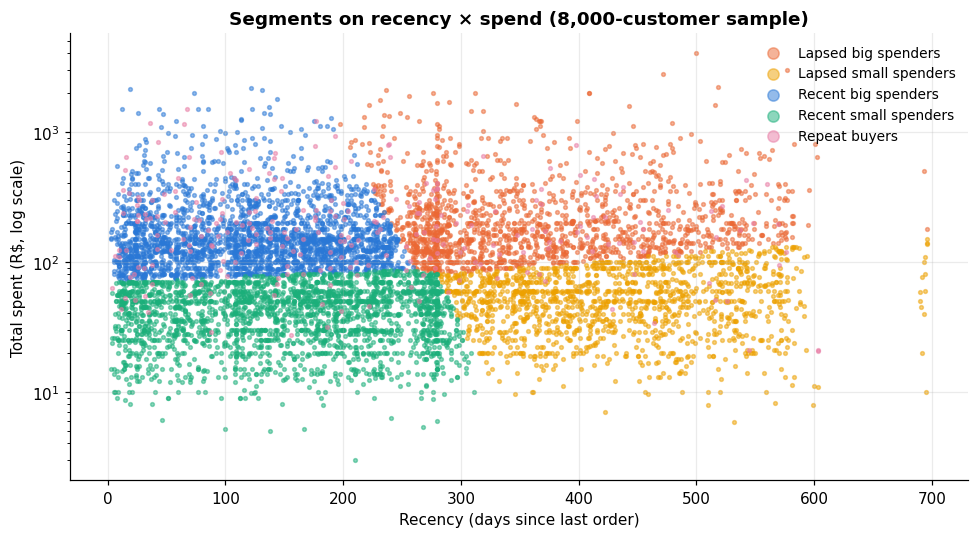

In [9]:
sample = segmented.sample(8_000, random_state=0).merge(segments[["segment"]], left_on="cluster", right_index=True)
palette = dict(zip(segments["segment"], ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
fig, ax = plt.subplots(figsize=(9, 5))
for name, group in sample.groupby("segment"):
    ax.scatter(group["recency_days"], group["monetary"], s=6, alpha=0.5, color=palette[name], label=name)
ax.set_yscale("log")
ax.set(xlabel="Recency (days since last order)", ylabel="Total spent (R$, log scale)",
       title="Segments on recency × spend (8,000-customer sample)")
ax.legend(frameon=False, markerscale=3, fontsize=9)
fig.tight_layout()
save(fig, "rfm_scatter")

**Where K-Means drew the lines:** in the scatter, "recent" vs "lapsed" splits at roughly 250–300 days (about 9 months) since the last order, and "big" vs "small" at roughly R\$ 80 of total spend. Nobody chose these cut-offs; the algorithm found them from the data.

## Findings

- **Lapsed big spenders** (no order for about a year, but high spend) are ~19% of customers yet ~36% of revenue. They are the most valuable **win-back** target.
- **Recent big spenders** bring the most revenue (~42%). The goal is a **second purchase** before they lapse, because only 3% of Olist customers ever buy twice.
- **Repeat buyers** are just 3% of customers but spend almost twice as much as the average customer (R\$ 260 vs R\$ 142). Protect them with loyalty perks and ask them for reviews and referrals.
- **Small spenders** (recent or lapsed) are ~49% of customers but only ~16% of revenue. Use cheap, automated channels only.

**Limitation:** with 97% one-time buyers, frequency carries little information, so these segments are driven mostly by recency and spend. A subscription business (like the Telco data in notebooks 2–3) gives a much richer behavioural picture.

In [10]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
segmented.merge(segments[["segment"]], left_on="cluster", right_index=True).to_csv(
    PROCESSED_DIR / "olist_customer_segments.csv", index=False)
segments.to_csv(PROCESSED_DIR / "olist_segment_profiles.csv")
print("saved")

saved
